# Example calculation of glass transition temperature (Tg) and coefficient of thermal expansion (CTE)

In [ ]:
from vast_pea.fitting import fit_tg_window_linear_intersection

import matplotlib.pyplot as plt
import numpy as np
from lammps_logfile import read_log

## Read the LAMMPS thermo log from the dilatometry protocol

In [ ]:
# using the lammps_logfile module
data = read_log("../../data/dilatometry/output.tg")

## Calculate average specific volume and temperature for each temperature step

In [ ]:
nb_temp = 21 # number of temperature steps
data_per_temp = 10 # number of data points per temperature step
# For this example, only the last 10 data points of each temperature step were kept in the logfile. However, in the publication, the last 0.5ns of each 2ns temperature step was taken instead

# storing the average and standard deviation for specific volume and temperature
volsp = [] # average specific volume
volsp_std = [] # standard deviation of specific volume
temp = [] # average temperature
temp_std = [] # standard deviation of temperature

# do average and standard deviation for each temperature step
for i in range(nb_temp):
    start = i + i*data_per_temp # beginning index of temperature step i
    end = i + i*data_per_temp + data_per_temp # end index of temperature step i

    section = data.loc[start:end] # section of the data corresponding to temperature step i

    volsp.append((1/section['Density']).mean()) # specific volume is calculated as 1/density
    volsp_std.append((1/section['Density']).std())
    temp.append(section['Temp'].mean())
    temp_std.append(section['Temp'].std())

# converting to np.array for further calculations
volsp = np.array(volsp)
volsp_std = np.array(volsp_std)
temp = np.array(temp)
temp_std = np.array(temp_std)

## Plot dilatometry data

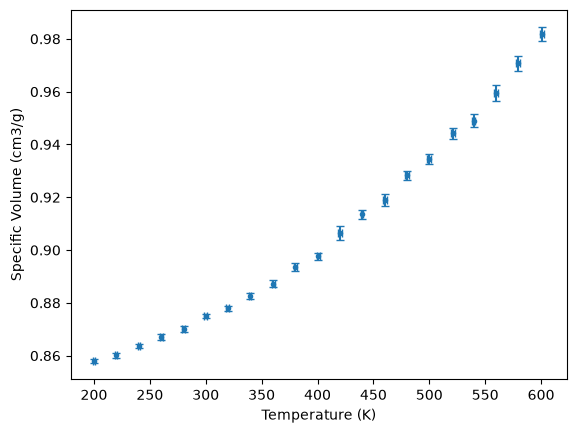

In [22]:
plt.errorbar(x=temp, y=volsp, xerr=temp_std, yerr=volsp_std, capsize=3, fmt='.')
plt.xlabel("Temperature (K)")
plt.ylabel("Specific Volume (cm3/g)")
plt.show()

## Fit dilatometry data with 2 linear fits and obtain Tg
This method defines the glassy and rubbery regimes as `tg±window` where `tg` is an initial empirical guess.
Choosing a large enough window enables the fits to not be dictated by this initial guess.

In [ ]:
fit = fit_tg_window_linear_intersection(x=temp, # temperature in K
                                        y=volsp, # specific volume in cm3/g
                                        tg=410, # initial guess for Tg
                                        window=70, # window around Tg for rubbery and glassy regimes
                                        verbose=True # print fit information
                                        )

Fitting extremum linear intersection:
	intersection : 404 ± -56 K
	intersection : 131 ± -56 C
	Start linear fit
	a_start : 0.0001726 ± 0.0000070 cm3/gK
	b_start : 0.8225 ± 0.0018 cm3/g
	R^2 : 0.99
	End linear fit
	a_end : 0.000443 ± 0.000022 cm3/gK
	b_start : 0.713 ± 0.012 cm3/g
	R^2 : 0.99


## Plot the 2 linear fits
Here, the glassy regime is colored in blue, the rubbery regime is colored in red and the data points within `tg±window` (so used by neither regimes) are colored in green

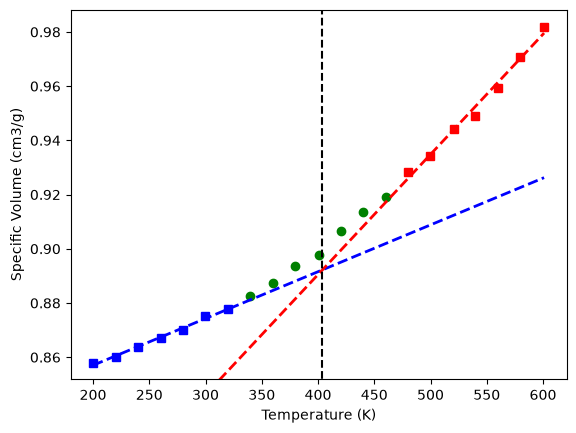

In [38]:
plt.plot(fit.x_start, fit.y_start, 'bs') # data points for glassy regime
plt.plot(fit.x_mid, fit.y_mid, 'og') # data points in the middle
plt.plot(fit.x_end, fit.y_end, 'rs') # data points in the rubbery regime

plt.plot(fit.x, fit.predict("start"), 'b--', linewidth=2) # fit for the glassy regime
plt.plot(fit.x, fit.predict("end"), 'r--', linewidth=2) # fit for the ruberry regime
plt.plot((fit.intersection, fit.intersection), (0, 1), 'k--') # intersection of both fits (Tg)

# just to resize the axis around the data
buffer_x = 0.05*(fit.x.max()-fit.x.min())
buffer_y = 0.05*(fit.y.max()-fit.y.min())
plt.xlim((fit.x.min()-buffer_x, fit.x.max()+buffer_x))
plt.ylim((fit.y.min()-buffer_y, fit.y.max()+buffer_y))

plt.xlabel("Temperature (K)")
plt.ylabel("Specific Volume (cm3/g)")
plt.show()

## Calculate CTEs
Here we study linear CTEs, which, for either the glassy or rubbery region, is the
$CTE = \frac{1}{3V}\frac{dV}{dT}$

In [40]:
# cte         = dV/dT           / V                  / 3 * convert to e-6 1/K
cte_start     = fit.a_start     / fit.y_start.mean() / 3 * 1e6
cte_start_err = fit.a_err_start / fit.y_start.mean() / 3 * 1e6
cte_end       = fit.a_end       / fit.y_end.mean()   / 3 * 1e6
cte_end_err   = fit.a_err_end   / fit.y_end.mean()   / 3 * 1e6

template = "{} : {:.4f} ± {:.4f} e-6 1/K"
print(template.format(
    "CTE in glassy regime",
    cte_start,
    cte_start_err
    ))
print(template.format(
    "CTE in rubbery regime",
    cte_end,
    cte_end_err
    ))

CTE in glassy regime : 66.3421 ± 2.6922 e-6 1/K
CTE in rubbery regime : 155.1469 ± 7.6668 e-6 1/K
